In [3]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
sns.set_theme(style="whitegrid")
usgs = pd.read_csv(os.path.join("data", "usgs_clean.csv"), parse_dates=["datetime"])
eq = pd.read_csv(os.path.join("data", "earthquakes_merged.csv"), parse_dates=["datetime"])

In [5]:
print(usgs.shape, eq.shape)
usgs.info()
eq.info()

(7753, 9) (1322, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7753 entries, 0 to 7752
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   usgs_id    7753 non-null   object 
 1   datetime   7753 non-null   object 
 2   latitude   7753 non-null   float64
 3   longitude  7753 non-null   float64
 4   depth_km   7753 non-null   float64
 5   magnitude  7753 non-null   float64
 6   magType    7753 non-null   object 
 7   place      7753 non-null   object 
 8   year       7753 non-null   int64  
dtypes: float64(4), int64(1), object(4)
memory usage: 545.3+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1322 entries, 0 to 1321
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   noaa_id           1322 non-null   int64  
 1   datetime_noaa     1322 non-null   object 
 2   country           1322 non-null   object 
 3   locationName      1322

In [6]:
eq.sample(5, random_state=421)

,noaa_id,datetime_noaa,country,locationName,latitude,longitude,noaa_depth_km,noaa_magnitude,deaths,injuries,damage_musd,houses_destroyed,usgs_id,datetime,depth_km,magnitude,magType,place,year
456,5479,1997-11-25 12:14:33.600000+00:00,INDONESIA,"INDONESIA: SULAWESI: MINAHASSA PENINSULA,GOR...",1.241,122.536,24.0,7.0,NaN,NaN,NaN,NaN,usp0008baj,1997-11-25 12:14:33.630000+00:00,24.000,7.0,mwc,"97 km NW of Gorontalo, Indonesia",1997
554,5677,1983-10-28 14:06:06.500000+00:00,USA,"IDAHO: BORAH PEAK, CHALLIS, MACKAY",43.974,-113.916,14.0,7.3,2.0,2.0,12.5,NaN,usp0001zbv,1983-10-28 14:06:06.610000+00:00,10.000,6.9,mw,"The 1983 Borah Peak Earthquake, Idaho",1983
295,5167,1988-08-20 23:09:09.500000+00:00,NEPAL,"NEPAL-INDIA: KATHMANDU, BIHAR",26.755,86.616,57.0,6.6,998.0,NaN,131.5,NaN,usp0003k6t,1988-08-20 23:09:09.560000+00:00,57.400,6.9,mw,"9 km WSW of Triyuga, Nepal",1988
829,8408,2009-09-29 17:48:10.900000+00:00,SAMOA,SAMOA ISLANDS,-15.489,-172.095,18.0,8.1,192.0,7.0,285.0,NaN,usp000h1ys,2009-09-29 17:48:10.990000+00:00,18.000,8.1,mwc,2009 Samoa Earthquake,2009
363,5321,1992-04-25 18:06:04.200000+00:00,USA,"CALIFORNIA: HUMBOLDT COUNTY: FERNDALE, PETROLIA",40.368,-124.316,15.0,7.1,NaN,98.0,75.0,NaN,nc269151,1992-04-25 18:06:05.180000+00:00,9.856,7.2,mw,"The 1992 Petrolia, California Earthquake",1992


In [7]:
print(usgs.isna().sum(), "\n")
print(eq.isna().sum(), "\n")
print("Duplicate usgs_id in usgs:", usgs["usgs_id"].duplicated().sum())
print("Duplicate usgs_id in eq:", eq["usgs_id"].duplicated().sum())
print("Duplicate noaa_id in eq:", eq["noaa_id"].duplicated().sum())

usgs_id      0
datetime     0
latitude     0
longitude    0
depth_km     0
magnitude    0
magType      0
place        0
year         0
dtype: int64 

noaa_id               0
datetime_noaa         0
country               0
locationName          0
latitude              0
longitude             0
noaa_depth_km         2
noaa_magnitude        0
deaths              684
injuries            686
damage_musd         943
houses_destroyed    999
usgs_id               0
datetime              0
depth_km              0
magnitude             0
magType               0
place                 0
year                  0
dtype: int64 

Duplicate usgs_id in usgs: 0
Duplicate usgs_id in eq: 0
Duplicate noaa_id in eq: 0


In [8]:
display(usgs[["magnitude", "depth_km"]].describe().T.round(2))
display(eq[["magnitude", "depth_km", "deaths"]].describe().T.round(2))
print("Skew:")
print(usgs[["magnitude", "depth_km"]].skew().round(2))

,count,mean,std,min,25%,50%,75%,max
magnitude,7753.0,6.38,0.42,6.0,6.1,6.23,6.57,9.1
depth_km,7753.0,74.55,131.86,-0.1,13.0,31.00,52.00,688.0


,count,mean,std,min,25%,50%,75%,max
magnitude,1322.0,6.84,0.58,6.0,6.4,6.8,7.25,9.1
depth_km,1322.0,39.16,70.94,-0.1,12.0,22.2,34.00,675.4
deaths,638.0,2349.35,19210.01,1.0,2.0,9.0,80.50,316000.0


Skew:
magnitude    1.67
depth_km     3.00
dtype: float64


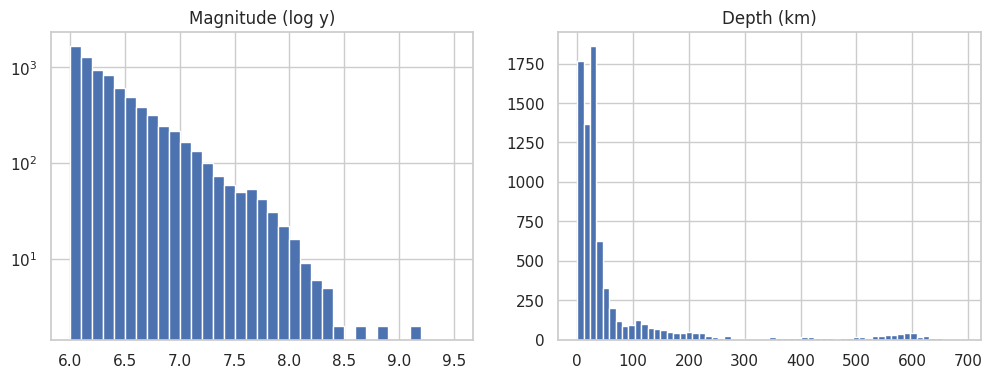

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(usgs["magnitude"], bins=np.arange(6, 9.6, 0.1))
axes[0].set_yscale("log")
axes[0].set_title("Magnitude (log y)")
axes[1].hist(usgs["depth_km"], bins=60)
axes[1].set_title("Depth (km)")
plt.show()

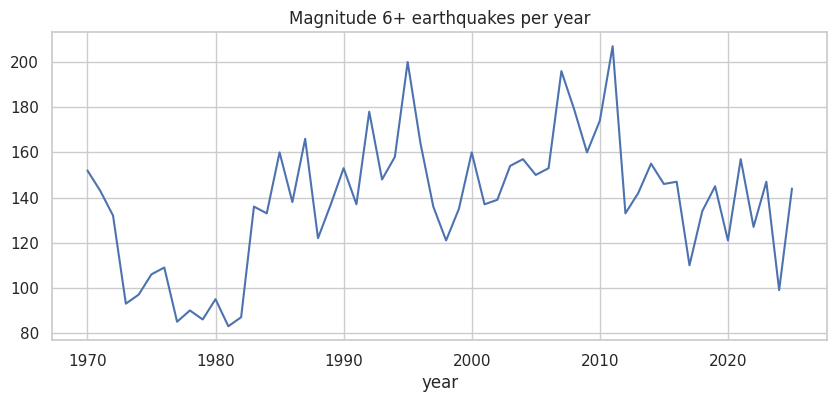

In [10]:
per_year = usgs.groupby("year").size()
per_year.plot(figsize=(10, 4), title="Magnitude 6+ earthquakes per year")
plt.show()

In [11]:
usgs["period"] = pd.cut(usgs["year"], [1969, 1984, 2025], labels=["1970-1984", "1985-2025"])
pd.crosstab(usgs["magType"], usgs["period"])

period,1970-1984,1985-2025
magType,,
mb,265,132
md,1,4
mh,0,1
ml,8,7
ms,647,58
mw,705,1425
mwb,0,924
mwc,1,1589
mwr,0,3


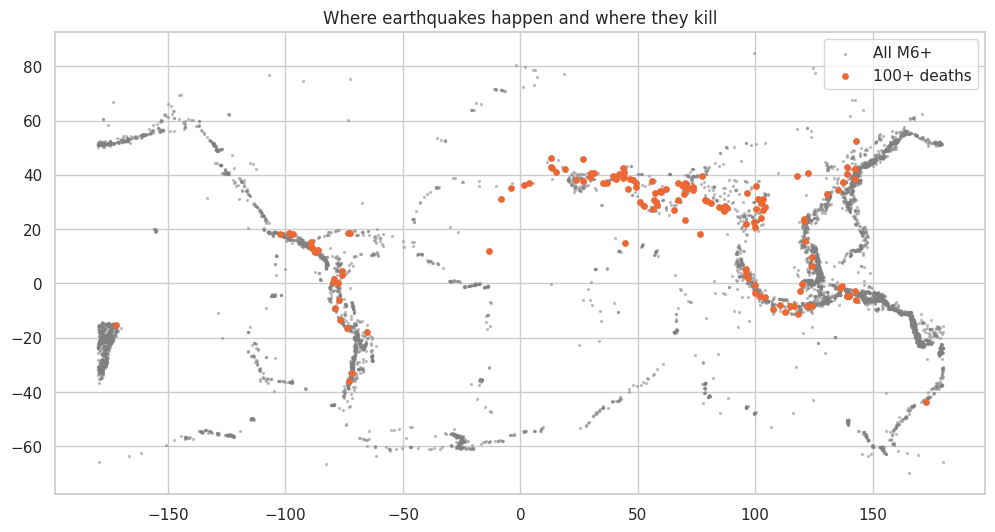

In [12]:
plt.figure(figsize=(12, 6))
plt.scatter(usgs["longitude"], usgs["latitude"], s=2, color="grey", alpha=0.4, label="All M6+")
deadly = eq[eq["deaths"] >= 100]
plt.scatter(deadly["longitude"], deadly["latitude"], s=15, color="#eb6834", label="100+ deaths")
plt.legend()
plt.title("Where earthquakes happen and where they kill")
plt.show()

In [13]:
display(eq["country"].value_counts().head(10))
display(eq.groupby("country")["deaths"].sum().sort_values(ascending=False).head(10))

,count
country,
INDONESIA,150
JAPAN,117
USA,69
CHINA,65
RUSSIA,57
PHILIPPINES,56
CHILE,54
IRAN,49
PAPUA NEW GUINEA,48


,deaths
country,
CHINA,372356.0
HAITI,318248.0
INDONESIA,254632.0
IRAN,106715.0
TURKEY,87467.0
PAKISTAN,82898.0
PERU,68010.0
INDIA,33339.0
JAPAN,26466.0


Pearson: 0.053
Spearman: 0.06


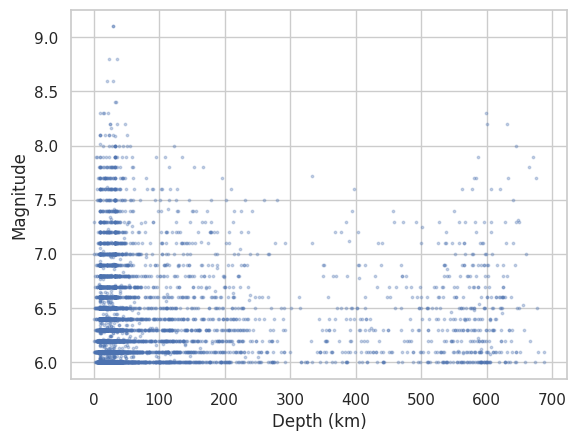

In [14]:
print("Pearson:", round(usgs["magnitude"].corr(usgs["depth_km"]), 3))
print("Spearman:", round(usgs["magnitude"].corr(usgs["depth_km"], method="spearman"), 3))
plt.scatter(usgs["depth_km"], usgs["magnitude"], s=3, alpha=0.3)
plt.xlabel("Depth (km)")
plt.ylabel("Magnitude")
plt.show()

Events with at least one recorded death: 638
Spearman (magnitude, deaths): 0.203


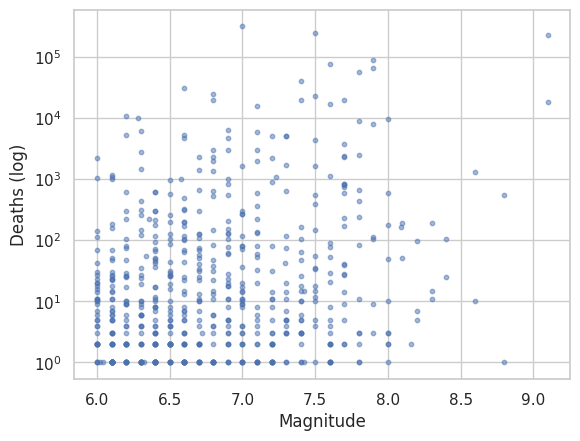

In [15]:
known = eq.dropna(subset=["deaths"]).copy()
print("Events with at least one recorded death:", len(known))
print("Spearman (magnitude, deaths):", round(known["magnitude"].corr(known["deaths"], method="spearman"), 3))
plt.scatter(known["magnitude"], known["deaths"], s=10, alpha=0.5)
plt.yscale("log")
plt.xlabel("Magnitude")
plt.ylabel("Deaths (log)")
plt.show()

In [16]:
known["depth_group"] = pd.cut(known["depth_km"], bins=[-1, 30, 70, 700],
                              labels=["shallow (≤ 30 km)", "intermediate (30-70 km)", "deep (> 70 km)"])
similar = known[(known["magnitude"] >= 6.5) & (known["magnitude"] < 7.0)]
display(similar.groupby("depth_group", observed=False)["deaths"].agg(["count", "median", "mean", "max"]).round(1))
display(similar.groupby("country")["deaths"].agg(["count", "median", "max"])
        .query("count >= 3").sort_values("median", ascending=False).head(10))

,count,median,mean,max
depth_group,,,,
shallow (≤ 30 km),108,22.0,1051.8,31000.0
intermediate (30-70 km),58,5.0,177.8,4700.0
deep (> 70 km),18,3.5,80.1,848.0


,count,median,max
country,,,
ITALY,3,978.0,4689.0
TURKEY,7,653.0,2311.0
CHINA,9,150.0,20000.0
IRAN,12,140.5,31000.0
INDIA,6,73.5,2000.0
USA,6,29.5,65.0
PAPUA NEW GUINEA,5,18.0,60.0
JAPAN,16,17.5,6434.0
AFGHANISTAN,8,12.5,4700.0


In [17]:
# Robustness check: remove USGS default depths (10 and 33 km)
print("Default depth 10 km:", (usgs["depth_km"] == 10).sum(), "| 33 km:", (usgs["depth_km"] == 33).sum())
s2 = similar[~similar["depth_km"].isin([10, 33])]
s2.groupby("depth_group", observed=False)["deaths"].agg(["count", "median"])

Default depth 10 km: 1212 | 33 km: 898


,count,median
depth_group,,
shallow (≤ 30 km),91,16.0
intermediate (30-70 km),37,4.0
deep (> 70 km),18,3.5
